# Partición en el tiempo con validación para P2 — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P2 (clasificación) · Semana 6  
**Autor:** Roberto Robles · **Rama:** `feature/p2-mlflow-experimentos`  
**Antecedentes:** `1.2-rr-p2-exploracion-flujo-neto.ipynb` (regla de riesgo) y `equipo52_module/modeling/train_p2.py` (entrenamiento).

**Propósito.** Calcular, como referencia, la partición en el tiempo y las métricas del baseline de P2 con las mismas funciones de `train_p2.py`: filas de entrenamiento, validación y prueba, F1 de fallas del baseline y desbalance de clases. Las corridas oficiales lanzadas con `mlflow run` deben coincidir con estas cifras; si no coinciden, hay un error en la ejecución. Además se comprueba que el entrenamiento final y la prueba son los mismos de la semana 5 y que no hay fuga de información entre periodos. De aquí salen las cifras de la sección 3.2 del reporte.

**Por qué se agregó validación.** En la semana 5 solo había entrenamiento y prueba. Para elegir hiperparámetros en la búsqueda (nested runs) necesitamos medir sin mirar la prueba: si eligiéramos con la prueba, su resultado ya no sería una estimación honesta de cómo le irá al modelo con datos nuevos.

Este notebook no entrena ni registra nada en MLflow: es la referencia contra la que se comparan las corridas oficiales.

In [2]:
# Objetivo: preparar el entorno e importar las mismas funciones y constantes que usa train_p2.py.
# Resultado esperado: las fechas de corte de la partición.

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # raíz del proyecto, para importar el módulo
from equipo52_module.config import (DURACION_MINIMA_SEGUNDOS, ESTACIONES_EXCLUIDAS, FECHA_FIN, FECHA_INICIO,
                                    INICIO_POSTCOVID, NOMENCLATURA_FILE, VIAJES_FILE)
from equipo52_module.features import NOMBRES_CLASES, construir_tabla_p2, quitar_viajes_cortos
from equipo52_module.modeling import train_p2 as p2

print("Inicio de entrenamiento (completo):  ", FECHA_INICIO)
print("Inicio de entrenamiento (Post-Covid):", INICIO_POSTCOVID)
print("Inicio de validación:                ", p2.INICIO_VALIDACION)
print("Inicio de prueba:                    ", p2.INICIO_PRUEBA)
print("Fin de prueba:                       ", FECHA_FIN)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Inicio de entrenamiento (completo):   2014-12-01
Inicio de entrenamiento (Post-Covid): 2023-05-09
Inicio de validación:                 2025-10-01
Inicio de prueba:                     2026-04-01
Fin de prueba:                        2026-09-30


## 1. La tabla estación × hora

Igual que en el script: se leen los viajes, se quitan los menores a 1 minuto y las estaciones excluidas, y se arma una fila por estación y hora con sus variables y su clase (normal, sin bicicletas o sin anclajes). Tarda alrededor de un minuto.

In [3]:
# Objetivo: construir la misma tabla que usa train_p2.py.
# Resultado esperado: alrededor de 28 millones de filas estación × hora.

viajes = quitar_viajes_cortos(pd.read_parquet(VIAJES_FILE), DURACION_MINIMA_SEGUNDOS)
estaciones = p2.cargar_estaciones(NOMENCLATURA_FILE, ESTACIONES_EXCLUIDAS)
tabla = construir_tabla_p2(viajes, estaciones, p2.HORAS_ANTICIPACION, p2.UMBRAL_FALLA, p2.SEMANAS_HISTORIAL)
del viajes  # libera memoria: ya no se necesita
print(f"Filas: {len(tabla):,} · columnas: {len(tabla.columns)}")
tabla.head()

Filas: 28,029,468 · columnas: 19


,estacion_id,hora,salidas,llegadas,clase,hora_del_dia,dia_semana,mes,fin_de_semana,salidas_hora_anterior,salidas_3_horas_anteriores,llegadas_hora_anterior,llegadas_3_horas_anteriores,semanas_sin_bicicletas,semanas_sin_anclajes,clase_semana_anterior,capacidad,latitud,longitud
0,2,2014-12-01 18:00:00,1,0,0,18,0,12,0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,15,20.666378,-103.34882
1,2,2014-12-01 19:00:00,0,0,0,19,0,12,0,1.0,NaN,0.0,NaN,NaN,NaN,<NA>,15,20.666378,-103.34882
2,2,2014-12-01 20:00:00,0,1,0,20,0,12,0,0.0,NaN,0.0,NaN,NaN,NaN,<NA>,15,20.666378,-103.34882
3,2,2014-12-01 21:00:00,0,1,0,21,0,12,0,0.0,1.0,1.0,1.0,NaN,NaN,<NA>,15,20.666378,-103.34882
4,2,2014-12-01 22:00:00,1,0,0,22,0,12,0,0.0,0.0,1.0,2.0,NaN,NaN,<NA>,15,20.666378,-103.34882


## 2. Los cuatro conjuntos

`partir_en_el_tiempo` devuelve cuatro conjuntos. Entre uno y el siguiente se recortan las últimas **3 horas** (función `entre`): la etiqueta de una hora mira las 3 horas siguientes, así que sin el recorte el entrenamiento "vería" el inicio de la validación o de la prueba.

| Conjunto | Para qué se usa |
|---|---|
| entrenamiento | Entrenar el modelo que se mide con validación |
| validación | Elegir modelo e hiperparámetros (métricas `val_*`) |
| entrenamiento final = entrenamiento + validación | Reentrenar el modelo que se registra (el mismo periodo de la semana 5) |
| prueba | Medir el modelo final (métricas `test_*`), igual que en la semana 5 |

In [4]:
# Objetivo: ver fechas, filas, estaciones y proporción de clases de cada conjunto.
# Resultado esperado: entrenamiento final 26,185,615 filas y prueba 1,842,173 (las mismas de la semana 5).

partes = p2.partir_en_el_tiempo(tabla, FECHA_INICIO)
resumen = pd.DataFrame({
    nombre: {
        "desde": datos["hora"].min(), "hasta": datos["hora"].max(), "filas": len(datos),
        "estaciones": datos["estacion_id"].nunique(),
        **(datos["clase"].map(NOMBRES_CLASES).value_counts(normalize=True) * 100).round(2).add_prefix("% ").to_dict(),
    }
    for nombre, datos in partes.items()
}).T
resumen

,desde,hasta,filas,estaciones,% normal,% sin_bicicletas,% sin_anclajes
entrenamiento,2014-12-01 00:00:00,2025-09-30 21:00:00,24566877,369,90.34,4.98,4.69
validacion,2025-10-01 00:00:00,2026-03-31 21:00:00,1618000,371,91.8,4.07,4.13
entrenamiento_final,2014-12-01 00:00:00,2026-03-31 21:00:00,26185615,371,90.43,4.92,4.65
prueba,2026-04-01 00:00:00,2026-09-30 22:00:00,1842173,469,93.48,3.12,3.4


In [9]:
# Objetivo: comprobar con números que la comparación contra la semana 5 sigue siendo válida.
# Resultado esperado: tres comprobaciones en True.

print("Entrenamiento final = semana 5:", len(partes["entrenamiento_final"]) == 26_185_615)
print("Prueba = semana 5:             ", len(partes["prueba"]) == 1_842_173)
# Entrenamiento + validación no suman exacto el entrenamiento final: entre los dos se recortan 3 horas.
hueco = len(partes["entrenamiento_final"]) - len(partes["entrenamiento"]) - len(partes["validacion"])
print("Filas del recorte de 3 horas entre entrenamiento y validación:", f"{hueco:,}", "→ positivo:", hueco > 0)

Entrenamiento final = semana 5: True
Prueba = semana 5:              True
Filas del recorte de 3 horas entre entrenamiento y validación: 738 → positivo: True


## 3. La partición en una línea de tiempo

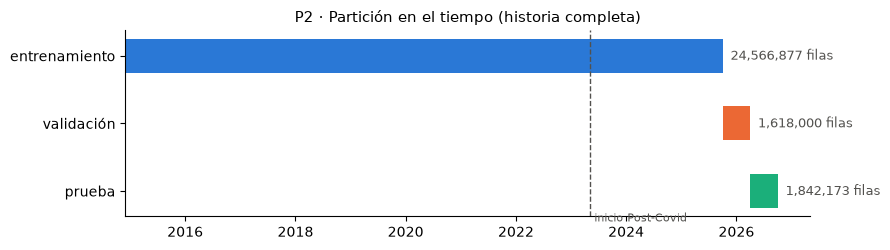

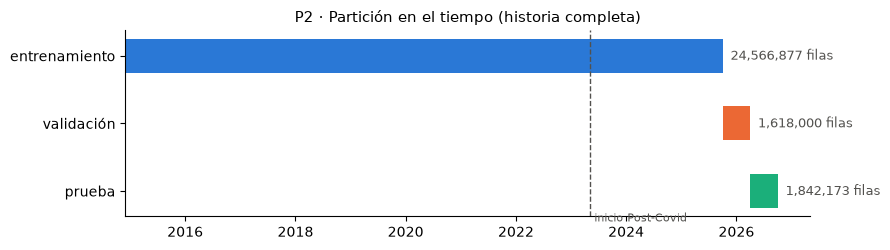

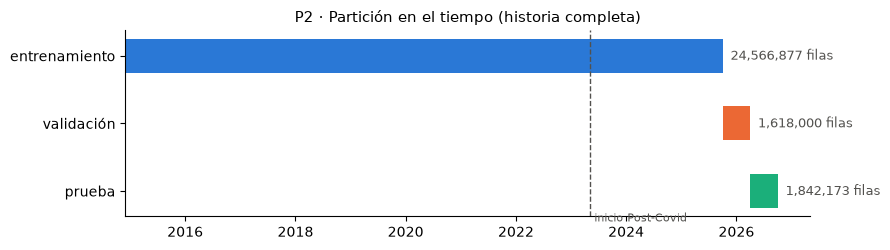

In [10]:
# Objetivo: dibujar los periodos para ver de un vistazo qué parte de la historia usa cada conjunto.
# Resultado esperado: entrenamiento largo (2014-2025), validación y prueba de 6 meses cada una.

%matplotlib inline
colores = {"entrenamiento": "#2a78d6", "validacion": "#eb6834", "prueba": "#1baf7a"}
fig, ax = plt.subplots(figsize=(9, 2.6))
for fila, nombre in enumerate(["entrenamiento", "validacion", "prueba"]):
    inicio, fin = partes[nombre]["hora"].min(), partes[nombre]["hora"].max()
    ax.barh(fila, fin - inicio, left=inicio, color=colores[nombre], height=0.5)
    ax.text(fin, fila, f"  {len(partes[nombre]):,} filas", va="center", fontsize=9, color="#52514e")
ax.axvline(pd.Timestamp(INICIO_POSTCOVID), color="#52514e", linestyle="--", linewidth=1)
ax.text(pd.Timestamp(INICIO_POSTCOVID), 2.45, " inicio Post-Covid", fontsize=8, color="#52514e")
ax.set_yticks(range(3), ["entrenamiento", "validación", "prueba"])
ax.invert_yaxis()
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
ax.set_title("P2 · Partición en el tiempo (historia completa)", fontsize=11)
plt.tight_layout()
plt.show()

## 4. El baseline en validación y en prueba

El baseline no entrena: repite lo que pasó en las últimas 4 semanas a la misma hora y día. Por eso se puede medir directo en los dos periodos. Esto es lo que verás en MLflow como `val_*` y `test_*` en la corrida `p2-base-completo`.

In [12]:
# Objetivo: calcular las métricas del baseline en validación y prueba con las funciones del script.
# Resultado esperado: F1 de fallas 0.442 en validación y 0.405 en prueba.

metricas = {}
for nombre, prefijo in [("validacion", "val"), ("prueba", "test")]:
    datos = partes[nombre]
    metricas[nombre] = {k.removeprefix(prefijo + "_"): round(v, 3) for k, v in
                        p2.calcular_metricas(datos["clase"].astype(int).to_numpy(), p2.predecir_con_base(datos),
                                             prefijo).items()}
pd.DataFrame(metricas)

,validacion,prueba
exactitud,0.910,0.927
f1_fallas,0.442,0.405
recall_sin_bicicletas,0.403,0.333
precision_sin_bicicletas,0.410,0.387
f1_sin_bicicletas,0.406,0.358
recall_sin_anclajes,0.475,0.437
precision_sin_anclajes,0.479,0.467
f1_sin_anclajes,0.477,0.451


In [13]:
# Objetivo: entender por qué la prueba es más difícil que la validación.
# Resultado esperado: 98 estaciones con viajes que solo aparecen en la prueba (abiertas en 2026); el baseline
# baja con ellas (0.323) frente a las que tienen historia (0.406).

en_validacion = set(partes["validacion"]["estacion_id"])
solo_en_prueba = set(partes["prueba"]["estacion_id"]) - en_validacion
print(f"Estaciones en validación: {len(en_validacion)} · solo en prueba: {len(solo_en_prueba)}")
nuevas = partes["prueba"]["estacion_id"].isin(solo_en_prueba)
for grupo, datos in [("estaciones nuevas", partes["prueba"][nuevas]), ("estaciones con historia", partes["prueba"][~nuevas])]:
    f1 = p2.calcular_metricas(datos["clase"].astype(int).to_numpy(), p2.predecir_con_base(datos), "test")["test_f1_fallas"]
    print(f"F1 de fallas del baseline en {grupo}: {f1:.3f}")

Estaciones en validación: 371 · solo en prueba: 98
F1 de fallas del baseline en estaciones nuevas: 0.323
F1 de fallas del baseline en estaciones con historia: 0.406


## 5. Desbalance de clases y `peso_fallas`

Casi todas las horas son normales. Un modelo que aprende con todas las horas pesando igual descubre que "normal" casi siempre es la respuesta segura: da pocas alertas, muy certeras, y se le escapan muchas fallas (es lo que pasó con HGB en la semana 5). El hiperparámetro **`peso_fallas`** hace que, al entrenar, cada hora de falla cuente como varias horas normales.

| Opción | Peso de cada hora de falla | Efecto esperado |
|---|---|---|
| sin pesos (`peso_fallas=1`) | 1 | Pocas alertas, muy certeras; muchas fallas se escapan |
| intermedio (`peso_fallas` = 2 a 8) | 2 a 8 | El equilibrio que busca la búsqueda con nested runs |
| `--balanceado` | el que iguala el peso total de cada clase (18 a 19, ver la tabla) | Muchas alertas falsas |

In [14]:
# Objetivo: calcular cuánto pesaría cada clase con --balanceado, para ubicar los valores intermedios.
# Resultado esperado: normal 0.37 y cada clase de falla alrededor de 7 (18 a 19 veces una hora normal).

y = partes["entrenamiento"]["clase"].astype(int)
conteo = y.value_counts().sort_index()
# Fórmula de scikit-learn para class_weight="balanced": total / (número de clases × filas de la clase)
balanceado = len(y) / (len(conteo) * conteo)
pd.DataFrame({"filas": conteo, "% del total": (conteo / len(y) * 100).round(2),
              "peso con --balanceado": balanceado.round(2),
              "relativo a normal": (balanceado / balanceado.loc[0]).round(1)}).rename(index=NOMBRES_CLASES)

,filas,% del total,peso con --balanceado,relativo a normal
clase,,,,
normal,22192678,90.34,0.37,1.0
sin_bicicletas,1222572,4.98,6.70,18.2
sin_anclajes,1151627,4.69,7.11,19.3


## 6. Conclusiones

1. **La comparación contra la semana 5 es válida.** El entrenamiento final (26,185,615 filas) y la prueba (1,842,173) son idénticos a los de la entrega anterior, y el baseline da el mismo F1 de fallas en prueba (0.405).
2. **No hay fuga de datos entre periodos.** Al final de cada periodo se quitan las horas cuya ventana de 3 horas cruzaría al siguiente: 2 horas por estación (738 filas = 2 × 369 estaciones entre entrenamiento y validación).
3. **La prueba es más difícil que la validación, sobre todo porque tiene menos fallas** (3.1 % y 3.4 % de las horas, contra 4.1 % en validación): el baseline baja de 0.442 a 0.405. Las 98 estaciones con viajes abiertas en 2026 solo aparecen en prueba y suman una dificultad extra (el baseline obtiene 0.323 en ellas y 0.406 en las que tienen historia), pero son pocas horas del total.
4. **`--balanceado` equivale a dar a cada hora de falla 18 a 19 veces el peso de una hora normal.** La rejilla de la búsqueda (`peso_fallas` = 2, 3, 5 y 8) explora la zona intermedia entre no dar pesos (1) y balancear.

**Dónde está cada cosa en el código:** `INICIO_VALIDACION`, `entre()` y `partir_en_el_tiempo()` en `train_p2.py`; las métricas en `calcular_metricas()`; los pesos en `pesos_por_clase()`.

**Cifras de referencia para las corridas oficiales.** Una corrida de P2 lanzada con `mlflow run` debe registrar exactamente estos valores; si alguno no coincide, hay un error en la ejecución.

| Qué | Valor de referencia | Dónde verlo en MLflow |
|---|---|---|
| Filas de entrenamiento (periodo completo) | 24,566,877 | parámetro `filas_entrenamiento` |
| Filas de validación | 1,618,000 | parámetro `filas_validacion` |
| Filas de entrenamiento final | 26,185,615 | parámetro `filas_entrenamiento_final` |
| Filas de prueba | 1,842,173 | parámetro `filas_prueba` |
| Baseline · F1 de fallas en validación | 0.442 | métrica `val_f1_fallas` de `p2-base-completo` |
| Baseline · F1 de fallas en prueba | 0.405 | métrica `test_f1_fallas` de `p2-base-completo` |